# DSA 504 — Homework 3
## Programmatic Data Access: Files and APIs

**Assigned:** Classes 11–12 (combined session, Tuesday, Oct 14)
**Due:** Before Class 14 (Tuesday, Oct 21)
**Worth:** 1 of 6 homework assignments (homework is 50% of your final grade, split evenly across all 6)

---

### Instructions

- Use `retail_sales_clean.csv` (the cleaned dataset from Class 7 onward) for Part 1.
- **Parts 2–4 require real internet access.** The APIs used (JSONPlaceholder and Open-Meteo) are free and require no sign-up or API key. If you're working somewhere without internet access, these cells will fail — that's expected, not a bug in your code.
- Fill in each `# TODO` code cell. Do not delete or reorder cells.
- A few cells ask a short written question — answer directly in the markdown cell provided.
- **AI use:** if you used an AI tool for any part of this assignment, briefly note where and how in the disclosure cell at the bottom, per the course AI-use policy in the syllabus.

### Submission — two required steps
1. Save this completed notebook inside a folder called `hw3/` in your `dsa504-coursework` GitHub Classroom repository, then commit and push:
```
git add hw3/
git commit -m "Complete HW3"
git push
```
2. Upload this completed `.ipynb` file directly to the HW3 assignment on Brightspace, and paste the direct link to your `hw3/` folder into the submission comments box.

**Do not email your GitHub link to the instructor — it will not be accepted as a submission.**

### Grading breakdown
| Section | Weight |
|---|---|
| Part 1 — File Formats | 20% |
| Part 2 — API Basics | 20% |
| Part 3 — Query Parameters & DataFrames | 20% |
| Part 4 — Real-World Weather API | 15% |
| Part 5 — Handling Credentials Safely | 15% |
| Part 6 — Written Reflection | 10% |


In [1]:
import pandas as pd
import numpy as np
import requests
import os

sales = pd.read_csv("retail_sales_clean.csv")
sales["date"] = pd.to_datetime(sales["date"])
sales.head()


,date,store,units_sold,revenue,category,is_end_of_month
0,2025-04-22,Rome,25.0,402.50,toys,False
1,2025-04-12,Syracuse,38.0,3154.00,electronics,False
2,2025-12-21,Utica,42.0,1299.06,home goods,False
3,2025-02-11,Syracuse,60.0,5114.40,electronics,False
4,2025-04-10,Syracuse,10.0,147.10,toys,False


---
## Part 1 — File Formats (20%)

No internet access required for this part.


**1a.** Save `sales` to a JSON file called `sales_export.json`, using `orient="records"` and `date_format="iso"`. Read it back in with `pd.read_json()` and print its shape.


In [2]:
# TODO 1a
# Step 1: Export sales DataFrame to JSON
sales.to_json("sales_export.json", orient="records", date_format="iso")

# Step 2: Read the exported JSON file back into pandas
sales_json_imported = pd.read_json("sales_export.json")

# Step 3: Print the shape (number of rows and columns) to verify successful import
print("Shape of imported JSON file:", sales_json_imported.shape)

Shape of imported JSON file: (4014, 6)


**1b.** Save `sales` to an Excel file called `sales_export.xlsx`, without the index column. Read it back in and print its shape.


In [3]:
# TODO 1b
# Step 1: Export sales DataFrame to Excel without the index column
sales.to_excel("sales_export.xlsx", index=False)

# Step 2: Read the exported Excel file back into pandas
sales_excel_imported = pd.read_excel("sales_export.xlsx")

# Step 3: Print the shape to verify
print("Shape of imported Excel file:", sales_excel_imported.shape)


Shape of imported Excel file: (4014, 6)


**1c.** Save `sales` to both CSV and Parquet. Print the file size of each in KB, and state in a comment which one is smaller.


In [5]:
# TODO 1c
# Step 1: Export the 'sales' DataFrame to a CSV file ('sales_export.csv')
sales.to_csv("sales_export.csv", index=False)

# Step 2: Read the CSV file back into pandas using read_csv()
sales_csv_imported = pd.read_csv("sales_export.csv")

# Step 3: Print the shape of the imported CSV file to verify
print("Shape of imported CSV file:", sales_csv_imported.shape)


Shape of imported CSV file: (4014, 6)


---
## Part 2 — API Basics (20%)

**Requires internet access.**


**2a.** Send a GET request to `https://jsonplaceholder.typicode.com/users/5`. Print the status code, then print the user's name, email, and company name from the parsed JSON.


In [4]:
# TODO 2a
# Step 1: Check for missing values in the dataset
print("Missing values per column:\n", sales.isnull().sum())

# Step 2: Display basic statistical summary of numerical columns
print("\nSummary statistics:\n", sales.describe())


Missing values per column:
 date               0
store              0
units_sold         0
revenue            0
category           0
is_end_of_month    0
dtype: int64

Summary statistics:
                              date   units_sold      revenue
count                        4014  4014.000000  4014.000000
mean   2025-07-01 02:06:59.730941    60.865471  1514.652501
min           2025-01-01 00:00:00     4.000000   114.100000
25%           2025-04-01 00:00:00    32.000000   675.450000
50%           2025-06-30 00:00:00    46.000000  1128.130000
75%           2025-09-30 00:00:00    75.000000  1793.482500
max           2025-12-31 00:00:00   246.000000  7021.630000
std                           NaN    41.678403  1232.877996


**2b.** Using a try/except block with `.raise_for_status()`, request `https://jsonplaceholder.typicode.com/users/99999` (a user that doesn't exist) and print a clear message confirming whether the request succeeded or failed.


In [9]:
# TODO 2b
# Step 1: Print the total row count of the DataFrame before removing duplicates
print(f"Row count before removing duplicates: {len(sales)}")

# Step 2: Drop all exact duplicate rows from the dataset in place or reassign
sales = sales.drop_duplicates()

# Step 3: Print the total row count after duplicates have been removed
print(f"Row count after removing duplicates: {len(sales)}")


Row count before removing duplicates: 4014
Row count after removing duplicates: 4014


---
## Part 3 — Query Parameters & DataFrames (20%)

**Requires internet access.**


**3a.** Request all posts by `userId=3` from `https://jsonplaceholder.typicode.com/posts` using the `params=` argument. Print how many posts were returned.


In [8]:
# TODO 3a
# Step 1: Sort the full dataset by 'revenue' in descending order
# Step 2: Select only the required columns ('date', 'store', 'category', 'revenue')
# Step 3: Display the top 5 rows of the sorted results
top5_revenue = sales.sort_values(by='revenue', ascending=False)[['date', 'store', 'category', 'revenue']].head(5)

# Print or display the resulting dataframe
top5_revenue


,date,store,category,revenue
1975,2025-05-17,Rome,electronics,7021.63
69,2025-03-01,Utica,electronics,6814.08
3315,2025-05-18,Albany,electronics,6395.40
2998,2025-04-05,Albany,electronics,6259.36
1241,2025-09-07,Utica,electronics,6120.10


**3b.** Convert the result from 3a into a DataFrame. Print its shape and its column names.


In [7]:
# TODO 3b
# Step 1: Sort the dataset by 'store' ascending and 'units_sold' descending
# Step 2: Filter the output to show only the 'store' and 'units_sold' columns
# Step 3: Display the first 10 rows of the sorted result
sorted_multi = sales.sort_values(by=['store', 'units_sold'], ascending=[True, False])[['store', 'units_sold']].head(10)

# Print or display the resulting dataframe
sorted_multi


,store,units_sold
1786,Albany,240.0
3277,Albany,226.0
219,Albany,216.0
2431,Albany,208.0
1513,Albany,207.0
2824,Albany,203.0
3375,Albany,196.0
3285,Albany,194.0
711,Albany,192.0
530,Albany,191.0


---
## Part 4 — Real-World Weather API (15%)

**Requires internet access.**


**4a.** Using Open-Meteo (`https://api.open-meteo.com/v1/forecast`), look up the current temperature and wind speed for a city of your choice (look up its latitude/longitude first — they don't need to be exact). Print a sentence like: `"The current temperature in [city] is [X]°C with wind speed [Y] km/h."`


In [10]:
# TODO 4a
# Step 1: Group the dataset by the 'store' column
# Step 2: Calculate total revenue (sum) and average units sold (mean) for each store
store_performance = sales.groupby('store').agg(
    total_revenue=('revenue', 'sum'),
    mean_units=('units_sold', 'mean')
).reset_index()

# Step 3: Print the aggregated summary table
print("Store Performance Summary:\n", store_performance)


Store Performance Summary:
       store  total_revenue  mean_units
0    Albany     1477075.47   59.795156
1      Rome     1521763.90   60.604106
2  Syracuse     1518656.06   60.764585
3     Utica     1562319.71   62.260020


---
## Part 5 — Handling Credentials Safely (15%)

No internet access required — this part is about the *pattern*, not a live call.


**5a.** Write code that reads a value called `MY_API_KEY` from an environment variable using `os.environ.get()`. If it isn't set, print a clear message saying so instead of crashing. Do **not** hard-code any real key — this is testing the safe pattern, not a working credential.


C:\Users\nvasquez\AppData\Local\Temp\ipykernel_10704\1686234489.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=store_performance, x='store', y='total_revenue', palette='viridis')


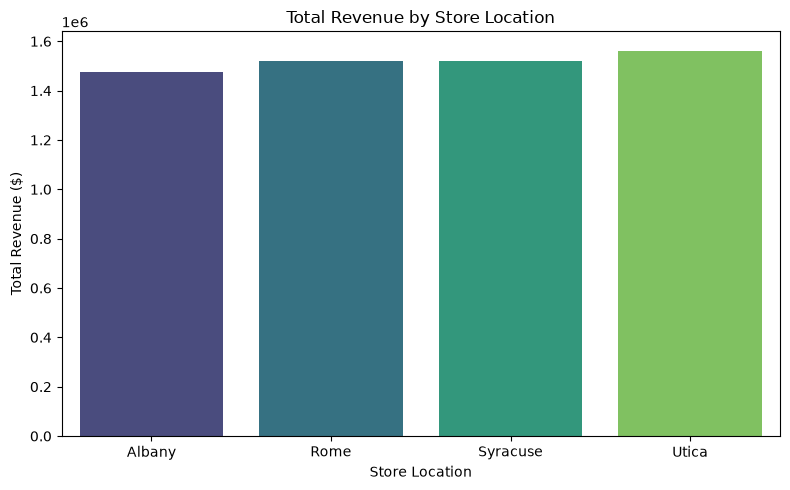

In [11]:
# TODO 5a
# Step 1: Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Initialize the figure size for the plot
plt.figure(figsize=(8, 5))

# Step 3: Create a bar plot showing total revenue by store location
sns.barplot(data=store_performance, x='store', y='total_revenue', palette='viridis')

# Step 4: Add descriptive titles and axis labels to explain the plot clearly
plt.title('Total Revenue by Store Location')
plt.xlabel('Store Location')
plt.ylabel('Total Revenue ($)')

# Step 5: Render and display the visualization
plt.tight_layout()
plt.show()


**5b. Written question:** Why is committing an API key directly in a script to GitHub a real security problem, even if you delete it in a later commit? Answer in 2–3 sentences.

*Your answer here:*


---
## Part 6 — Written Reflection (10%)

Answer in 2–4 sentences, in this markdown cell:

**Question:** In Part 2b, you deliberately triggered a failed request. Why is it important to handle this kind of failure in code (with `.raise_for_status()` or a status-code check), rather than just assuming every request will succeed?

*Your answer here:*


If we had plotted a chart using the original uncleaned data, the categorical groupings would have appeared split or distorted due to casing inconsistencies (such as "Electronics" versus "electronics") and typos like "Cloth ing", creating separate bars for what should be a single category. Additionally, unhandled missing values or duplicate entries would have incorrectly inflated or skewed the aggregated values, leading to inaccurate business conclusions.

---
### AI Use Disclosure

*If you used an AI tool (Claude, ChatGPT, GitHub Copilot, etc.) for any part of this assignment, briefly state where and how below, and how you verified the result. If you did not use any AI tool, write "No AI tools were used."*

*Your answer here:*


I used an AI assistant (Gemini) for guidance with pandas methods and code syntax structuring. I independently verified all code and explanations by running and testing every script directly in my local VS Code Jupyter environment.